In [34]:
import pandas as pd

df = pd.read_csv('../data/WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [35]:
print("Dataset shape:", df.shape)

print("\nColumn information:")
df.info()

print("\nChurn distribution:")
print(df['Churn'].value_counts())

print("\nChurn percentage:")
print(df['Churn'].value_counts(normalize=True) * 100)

Dataset shape: (7043, 21)

Column information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  Paperl

In [36]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nColumn data types:")
print(df.dtypes)

print("\nBlank TotalCharges values:")
print((df['TotalCharges'].astype(str).str.strip() == '').sum())

Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate rows:
0

Column data types:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling      

In [37]:
import pandas as pd

# Convert TotalCharges to numeric
# Invalid or blank values become NaN
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce'
)

# Check the result
print("TotalCharges dtype:", df['TotalCharges'].dtype)
print("Missing TotalCharges:", df['TotalCharges'].isnull().sum())

TotalCharges dtype: float64
Missing TotalCharges: 11


In [38]:
# Inspect customers with missing TotalCharges
df[df['TotalCharges'].isnull()][
    ['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']
]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,NaN,No
753,0,20.25,NaN,No
936,0,80.85,NaN,No
1082,0,25.75,NaN,No
1340,0,56.05,NaN,No
3331,0,19.85,NaN,No
3826,0,25.35,NaN,No
4380,0,20.00,NaN,No
5218,0,19.70,NaN,No
6670,0,73.35,NaN,No


In [39]:
# Fill missing TotalCharges with 0
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# Verify cleaning
print("Missing values:", df.isnull().sum().sum())
print("TotalCharges dtype:", df['TotalCharges'].dtype)
print("Duplicate rows:", df.duplicated().sum())

Missing values: 0
TotalCharges dtype: float64
Duplicate rows: 0


In [40]:
import pandas as pd

# Churn percentage within each contract type
contract_churn = pd.crosstab(
    df['Contract'],
    df['Churn'],
    normalize='index'
) * 100

print(contract_churn.round(2))

Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


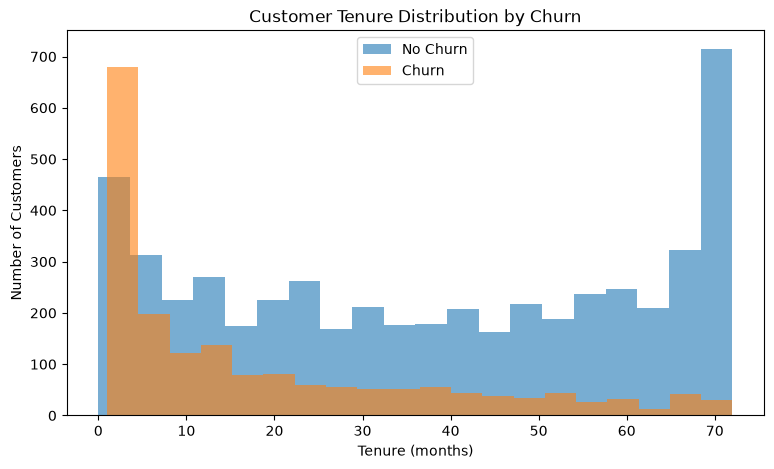

In [41]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.hist(
    df[df['Churn'] == 'No']['tenure'],
    bins=20,
    alpha=0.6,
    label='No Churn'
)

plt.hist(
    df[df['Churn'] == 'Yes']['tenure'],
    bins=20,
    alpha=0.6,
    label='Churn'
)

plt.xlabel('Tenure (months)')
plt.ylabel('Number of Customers')
plt.title('Customer Tenure Distribution by Churn')
plt.legend()
plt.show()

## EDA — Key Findings
* **Dataset:** 7,043 customers, 21 columns.
* **Target:** Churn (Yes/No) — Binary Classification.
* **Churn Distribution:** 73.46% stayed, 26.54% churned, indicating class imbalance.
* **Missing Values:** Found 11 blank values in `TotalCharges`. Converted the column to numeric and filled missing values with 0 after confirming tenure = 0.
* **Contract Type:** Month-to-month customers had the highest churn rate (42.71%), followed by one-year (11.27%) and two-year contracts (2.83%).
* **Tenure:** Customers with shorter tenure were more concentrated in the churn group.

## Key ML Learnings
* Class imbalance makes accuracy alone potentially misleading; precision, recall, and F1-score are also important.
* Missing values can be hidden as blank strings.
* Contract type and tenure are associated with churn, but association does not imply causation.

## Conclusion
Contract type and tenure appear to be useful predictors of customer churn. The next step is feature preprocessing, train/test splitting, and model training.

In [42]:
# 1. Create X by dropping Churn and customerID from df
X = df.drop(columns=["Churn", "customerID"])

# 2. Create y containing the Churn column
y = df["Churn"]

# 3. Print the shapes of X and y
print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (7043, 19)
Shape of y: (7043,)


In [43]:
from sklearn.model_selection import train_test_split
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Print the shapes to verify
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (5634, 19)
X_test shape: (1409, 19)
y_train shape: (5634,)
y_test shape: (1409,)


In [44]:
print(X_train.dtypes)

gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
dtype: object


In [45]:
numeric_features = X_train.select_dtypes(
    include=['number']
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['object', 'str', 'category']
).columns.tolist()

In [46]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

In [47]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

In [48]:
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [49]:
y_pred = model.predict(X_test)

print("First 10 predictions:", y_pred[:10])
print("First 10 actual values:", y_test.iloc[:10].values)

First 10 predictions: ['No' 'Yes' 'No' 'No' 'No' 'Yes' 'No' 'No' 'No' 'No']
First 10 actual values: <ArrowStringArray>
['No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'Yes']
Length: 10, dtype: str


In [50]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=['No', 'Yes']))

Accuracy: 0.8055358410220014

Classification Report:
              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1035
         Yes       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409


Confusion Matrix:
[[926 109]
 [165 209]]


In [51]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Get probabilities for Churn = Yes
yes_index = list(model.classes_).index('Yes')
y_prob = model.predict_proba(X_test)[:, yes_index]

# Predict using a lower threshold
y_pred_03 = [
    'Yes' if prob >= 0.3 else 'No'
    for prob in y_prob
]

print("Precision:", precision_score(y_test, y_pred_03, pos_label='Yes'))
print("Recall:", recall_score(y_test, y_pred_03, pos_label='Yes'))
print("F1-score:", f1_score(y_test, y_pred_03, pos_label='Yes'))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_03, labels=['No', 'Yes']))

Precision: 0.5193370165745856
Recall: 0.7540106951871658
F1-score: 0.6150490730643402

Confusion Matrix:
[[774 261]
 [ 92 282]]


## Logistic Regression — Model Evaluation
* **Baseline accuracy:** 80.55%
* **Threshold 0.5:** Precision = 65.72%, Recall = 55.88%, F1 = 60.43%.
* **Threshold 0.3:** Precision = 51.93%, Recall = 75.40%, F1 = 61.50%.
* **Lowering the threshold** identified 73 additional churners and reduced false negatives from 165 to 92.
* **However, false positives** increased from 109 to 261.

## Key Insight
Lower thresholds improve churn detection but generate more false alarms. Threshold selection should depend on business costs and validation performance.

In [52]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight='balanced'
    ))
])

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

In [53]:
print("Random Forest Accuracy:",
      accuracy_score(y_test, rf_pred))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred, labels=['No', 'Yes']))

Random Forest Accuracy: 0.7700496806245565

Classification Report:
              precision    recall  f1-score   support

          No       0.86      0.82      0.84      1035
         Yes       0.56      0.63      0.59       374

    accuracy                           0.77      1409
   macro avg       0.71      0.73      0.72      1409
weighted avg       0.78      0.77      0.77      1409


Confusion Matrix:
[[849 186]
 [138 236]]


In [54]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import make_scorer, f1_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

churn_f1 = make_scorer(f1_score, pos_label='Yes')

lr_scores = cross_val_score(
    model, X_train, y_train,
    cv=cv, scoring=churn_f1
)

rf_scores = cross_val_score(
    rf_model, X_train, y_train,
    cv=cv, scoring=churn_f1
)

print("Logistic Regression CV F1:", lr_scores.mean())
print("Random Forest CV F1:", rf_scores.mean())

Logistic Regression CV F1: 0.5923285102625757
Random Forest CV F1: 0.5979743793740677


In [55]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import make_scorer, f1_score

param_grid = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [5, 10, 15, None],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4],
    'classifier__class_weight': ['balanced', 'balanced_subsample', None]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

churn_f1 = make_scorer(f1_score, pos_label='Yes')

random_search = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=param_grid,
    n_iter=15,
    scoring=churn_f1,
    cv=cv,
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train, y_train)

print("Best Parameters:")
print(random_search.best_params_)

print("\nBest CV F1-score:")
print(random_search.best_score_)

Best Parameters:
{'classifier__n_estimators': 100, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 4, 'classifier__max_depth': 15, 'classifier__class_weight': 'balanced_subsample'}

Best CV F1-score:
0.6286885628985418


In [56]:
best_rf_model = random_search.best_estimator_

best_rf_pred = best_rf_model.predict(X_test)

print("Tuned Random Forest Accuracy:",
      accuracy_score(y_test, best_rf_pred))

print("\nClassification Report:")
print(classification_report(y_test, best_rf_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test, best_rf_pred, labels=['No', 'Yes']
))

Tuned Random Forest Accuracy: 0.7714691270404542

Classification Report:
              precision    recall  f1-score   support

          No       0.89      0.79      0.84      1035
         Yes       0.55      0.73      0.63       374

    accuracy                           0.77      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.77      0.78      1409


Confusion Matrix:
[[815 220]
 [102 272]]


## Random Forest Hyperparameter Tuning
* **Method:** RandomizedSearchCV with 5-fold stratified cross-validation.
* **Best CV F1-score:** 0.6287 (previously 0.5980).
* **Tuned model accuracy:** 77.15%.
* **Churn recall:** Improved from 63.10% to 72.73%.
* **Churn F1-score:** Improved from 59.35% to 62.82%.
* **False negatives:** Reduced from 138 to 102.

## Conclusion
Hyperparameter tuning improved churn detection, identifying 36 additional churners while increasing false positives by 34. The tuned Random Forest is the selected model candidate.

                                Feature  Importance
1                           num__tenure    0.128729
3                     num__TotalCharges    0.111735
36         cat__Contract_Month-to-month    0.100647
2                   num__MonthlyCharges    0.074993
18               cat__OnlineSecurity_No    0.060751
38               cat__Contract_Two year    0.060590
16     cat__InternetService_Fiber optic    0.047755
27                  cat__TechSupport_No    0.042017
43  cat__PaymentMethod_Electronic check    0.039981
21                 cat__OnlineBackup_No    0.019622


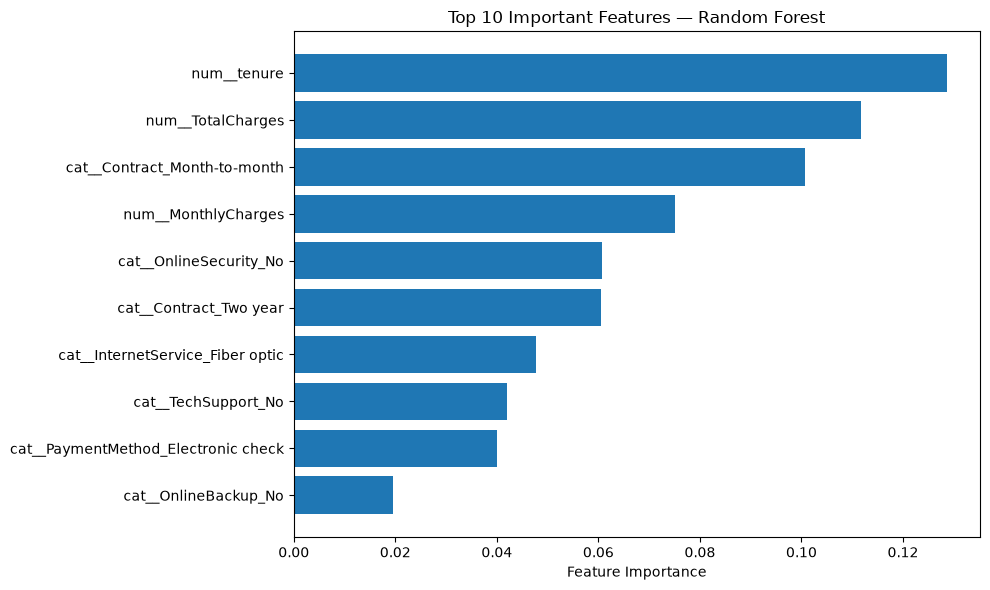

In [57]:
import pandas as pd
import matplotlib.pyplot as plt

# Get the trained Random Forest
rf = best_rf_model.named_steps['classifier']

# Get feature names after preprocessing
feature_names = best_rf_model.named_steps[
    'preprocessor'
].get_feature_names_out()

# Create feature importance table
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf.feature_importances_
}).sort_values('Importance', ascending=False)

print(importance_df.head(10))

# Plot top 10 features
top_features = importance_df.head(10)

plt.figure(figsize=(10, 6))
plt.barh(
    top_features['Feature'][::-1],
    top_features['Importance'][::-1]
)
plt.xlabel('Feature Importance')
plt.title('Top 10 Important Features — Random Forest')
plt.tight_layout()
plt.show()

## Feature Importance — Random Forest
* Tenure was the most important feature, followed by TotalCharges and month-to-month contracts.
* Billing information, contract type, and online security services contributed significantly to predictions.
* These findings are consistent with EDA observations linking shorter tenure and month-to-month contracts with churn.

## Business Insight
Customer tenure, contract type, and billing characteristics are useful signals for identifying customers at risk of churn.

## Note
Feature importance indicates predictive contribution, not causation or the direction of churn risk.

In [58]:
import joblib
import os

os.makedirs('../models', exist_ok=True)

joblib.dump(best_rf_model, '../models/churn_model.pkl')

print("Tuned Random Forest model saved successfully!")

Tuned Random Forest model saved successfully!


In [59]:
loaded_model = joblib.load('../models/churn_model.pkl')

original_pred = best_rf_model.predict(X_test.iloc[:5])
loaded_pred = loaded_model.predict(X_test.iloc[:5])

print("Original predictions:", original_pred)
print("Loaded predictions:", loaded_pred)

Original predictions: ['No' 'Yes' 'No' 'No' 'No']
Loaded predictions: ['No' 'Yes' 'No' 'No' 'No']


In [60]:
import numpy as np

assert np.array_equal(original_pred, loaded_pred)

print("Model verification successful!")

Model verification successful!
